In [16]:
#Inflation Shock Prediction
#Hareem Khawar (Bseds 23030) and Basil Butt (Bseds 23006)

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cpi=pd.read_csv('CPILFESL.csv',parse_dates=['observation_date'])
wti=pd.read_csv('WTISPLC.csv',parse_dates=['observation_date'])
ppi=pd.read_csv('PPIACO.csv',parse_dates=['observation_date'])
m2v=pd.read_csv('M2V.csv',parse_dates=['observation_date'])

cpi=cpi.rename(columns={'observation_date':'date','CPILFESL':'core_cpi'})
wti=wti.rename(columns={'observation_date':'date','WTISPLC':'wti_oil'})
ppi=ppi.rename(columns={'observation_date':'date','PPIACO':'ppi'})
m2v=m2v.rename(columns={'observation_date':'date','M2V':'m2_velocity'})

cpi['core_cpi']=pd.to_numeric(cpi['core_cpi'],errors='coerce')
cpi['core_cpi']=cpi['core_cpi'].interpolate(method='linear')

df=pd.merge(cpi,wti,on='date',how='left')
df=pd.merge(df,ppi,on='date',how='left')
df=pd.merge(df,m2v,on='date',how='left')

df['m2_velocity']=df['m2_velocity'].ffill()

df=df[(df['date']>='1986-09-01')&(df['date']<='2026-08-01')].copy()
df=df.sort_values('date').reset_index(drop=True)

print(df.shape)
print(df.isnull().sum())

(480, 5)
date           0
core_cpi       0
wti_oil        0
ppi            0
m2_velocity    0
dtype: int64


In [18]:
df['cpi_pct_change']=df['core_cpi'].pct_change()*100
df['ppi_pct_change']=df['ppi'].pct_change()*100
df['wti_pct_change']=df['wti_oil'].pct_change()*100

df=df.dropna().reset_index(drop=True)

df['shock_next_month']=(df['cpi_pct_change']>0.4).astype(int).shift(-1)
df=df.dropna().reset_index(drop=True)

print(df['shock_next_month'].value_counts())

shock_next_month
0.0    439
1.0     39
Name: count, dtype: int64


In [19]:
print(df.describe())
print(df.median(numeric_only=True))
print(df.mode(numeric_only=True).iloc[0])

                                date    core_cpi     wti_oil         ppi  \
count                            478  478.000000  478.000000  478.000000   
mean   2006-08-16 10:59:44.937238528  210.391041   49.241962  168.044266   
min              1986-10-01 00:00:00  115.000000   11.280000   99.700000   
25%              1996-09-08 12:00:00  166.575000   20.577250  125.100000   
50%              2006-08-16 12:00:00  207.000000   45.330000  165.700000   
75%              2016-07-24 06:00:00  248.274500   71.852500  200.700000   
max              2026-07-01 00:00:00  336.789000  133.930000  290.200000   
std                              NaN   56.538852   29.411899   48.420096   

       m2_velocity  cpi_pct_change  ppi_pct_change  wti_pct_change  \
count   478.000000      478.000000      478.000000      478.000000   
mean      1.753981        0.225872        0.226175        0.793422   
min       1.126000       -0.489789       -5.332656      -43.341321   
25%       1.462000        0.146007 

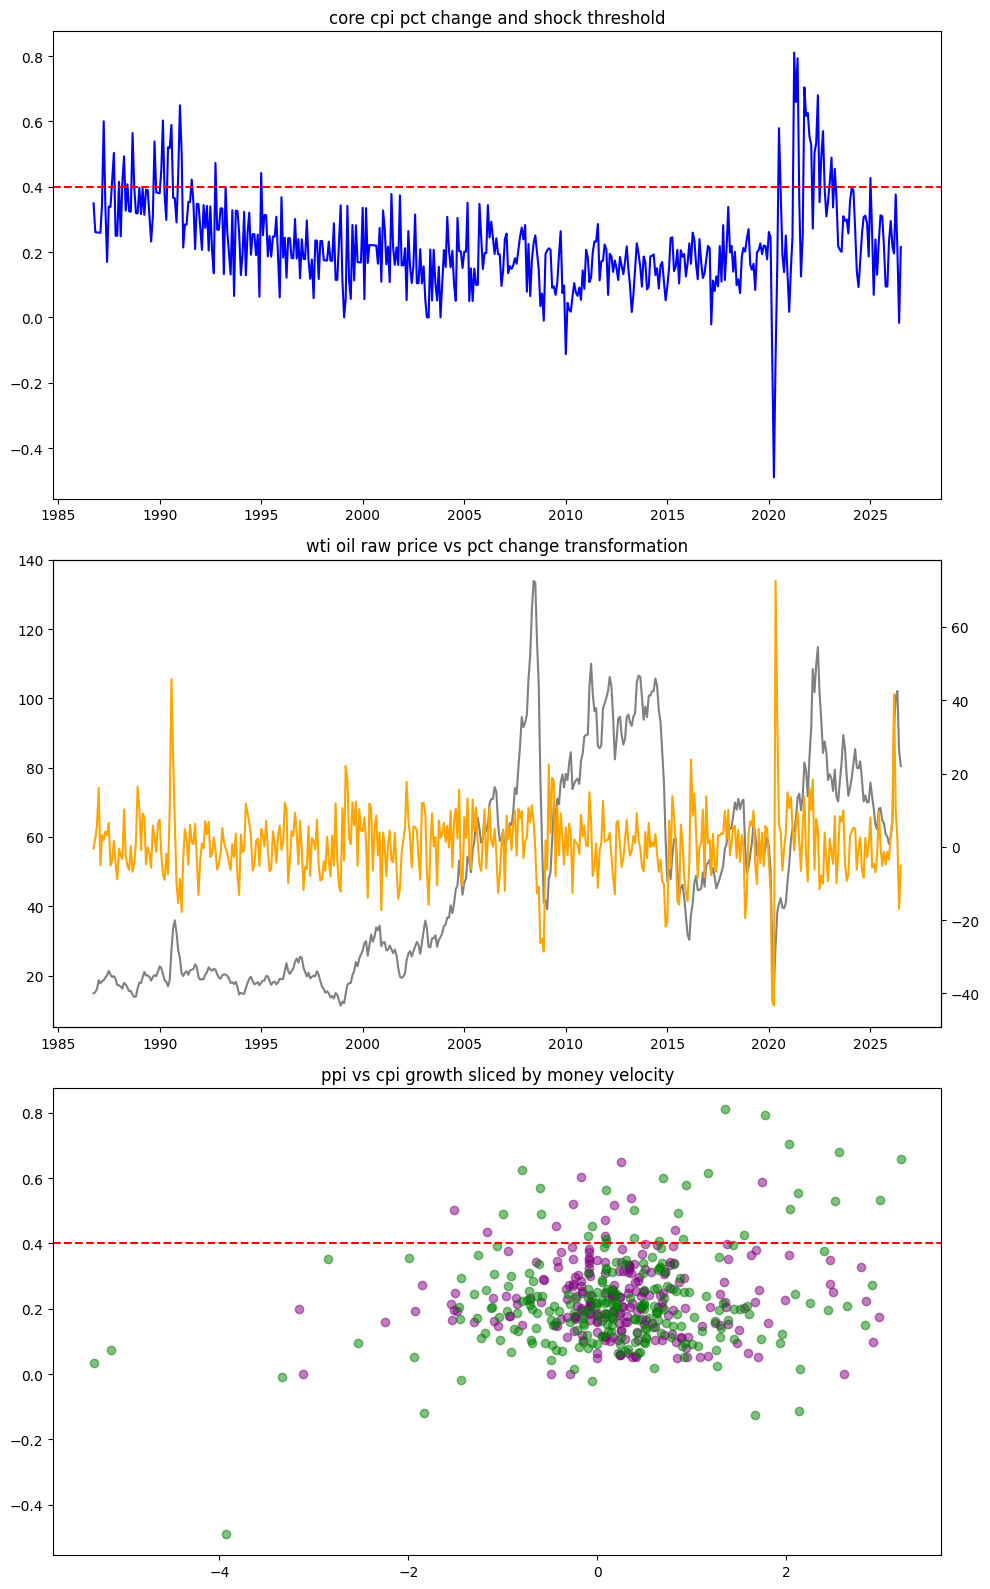

In [20]:
fig,axes=plt.subplots(3,1,figsize=(10,16))

axes[0].plot(df['date'],df['cpi_pct_change'],color='blue')
axes[0].axhline(0.4,color='red',linestyle='--')
axes[0].set_title('core cpi pct change and shock threshold')

ax2=axes[1].twinx()
axes[1].plot(df['date'],df['wti_oil'],color='gray')
ax2.plot(df['date'],df['wti_pct_change'],color='orange')
axes[1].set_title('wti oil raw price vs pct change transformation')

m2v_med=df['m2_velocity'].median()
high_m2v=df[df['m2_velocity']>m2v_med]
low_m2v=df[df['m2_velocity']<=m2v_med]

axes[2].scatter(high_m2v['ppi_pct_change'],high_m2v['cpi_pct_change'],color='purple',alpha=0.5)
axes[2].scatter(low_m2v['ppi_pct_change'],low_m2v['cpi_pct_change'],color='green',alpha=0.5)
axes[2].axhline(0.4,color='red',linestyle='--')
axes[2].set_title('ppi vs cpi growth sliced by money velocity')

plt.tight_layout()
plt.show()